# ¡Llena ese carrito!


# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución. También escribe una conclusión que resuma tus hallazgos y elecciones.


## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
  - `'order_id'`: número de ID que identifica de manera única cada pedido.
  - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
  - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
  - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
  - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
  - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
  - `'product_id'`: número ID que identifica de manera única cada producto.
  - `'product_name'`: nombre del producto.
  - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
  - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
  - `'order_id'`: número de ID que identifica de manera única cada pedido.
  - `'product_id'`: número ID que identifica de manera única cada producto.
  - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
  - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
  - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
  - `'aisle'`: nombre del pasillo.
- `departments.csv`
  - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
  - `'department'`: nombre del departamento.


# Paso 1. Descripción de los datos

Lee los archivos de datos (`/datasets/instacart_orders.csv`, `/datasets/products.csv`, `/datasets/aisles.csv`, `/datasets/departments.csv` y `/datasets/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.


In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# leer conjuntos de datos en los DataFrames (los archivos están separados por punto y coma)
# Primero se intenta la ruta de la plataforma (/datasets/); si no existe, se leen los archivos locales
try:
    instacart_orders = pd.read_csv("/datasets/instacart_orders.csv", sep=';')
    products = pd.read_csv("/datasets/products.csv", sep=';')
    aisles = pd.read_csv("/datasets/aisles.csv", sep=';')
    departments = pd.read_csv("/datasets/departments.csv", sep=';')
    order_products = pd.read_csv("/datasets/order_products.csv", sep=';')
except FileNotFoundError:
    instacart_orders = pd.read_csv("instacart_orders.csv", sep=';')
    products = pd.read_csv("products.csv", sep=';')
    aisles = pd.read_csv("aisles.csv", sep=';')
    departments = pd.read_csv("departments.csv", sep=';')
    order_products = pd.read_csv("order_products.csv", sep=';')

In [3]:
# mostrar información del DataFrame
instacart_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


In [4]:
# mostrar información del DataFrame
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     49694 non-null  int64
 1   product_name   48436 non-null  str  
 2   aisle_id       49694 non-null  int64
 3   department_id  49694 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.5 MB


In [5]:
# mostrar información del DataFrame
aisles.info()

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int64
 1   aisle     134 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.2 KB


In [6]:
# mostrar información del DataFrame
departments.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   department_id  21 non-null     int64
 1   department     21 non-null     str  
dtypes: int64(1), str(1)
memory usage: 468.0 bytes


In [7]:
# mostrar información del DataFrame
order_products.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


## Conclusiones

Los cinco archivos usan punto y coma (`;`) como separador, por eso se leen con `sep=';'`. Con esa lectura, `.info()` muestra que todas las tablas se cargaron con sus columnas correctas:

- `instacart_orders`: 478,967 filas y 6 columnas. Las columnas de ID, número de pedido, día y hora son `int64`. `days_since_prior_order` es `float64` y es la única con valores ausentes.
- `products`: 49,694 filas y 4 columnas. Los ID son `int64` y `product_name` es texto, con valores ausentes.
- `aisles` (134 filas) y `departments` (21 filas): completas, sin valores ausentes.
- `order_products`: 4,545,007 filas y 4 columnas. Con `show_counts=True` se confirma que `add_to_cart_order` tiene valores ausentes; por eso aparece como `float64` aunque representa una posición entera.

En el Paso 2 se tratan los duplicados, los valores ausentes y los tipos de estas columnas.


# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:

- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?


In [8]:
print(instacart_orders.duplicated().sum())
print(products.duplicated().sum())
print(aisles.duplicated().sum())
print(departments.duplicated().sum())
print(order_products.duplicated().sum())

15
0
0
0


0


In [9]:
print(instacart_orders.isna().sum())
print("="*50)
print(products.isna().sum())
print("="*50)
print(aisles.isna().sum())
print("="*50)
print(departments.isna().sum())
print("="*50)
print(order_products.isna().sum())

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28819
dtype: int64
product_id          0
product_name     1258
aisle_id            0
department_id       0
dtype: int64
aisle_id    0
aisle       0
dtype: int64
department_id    0
department       0
dtype: int64
order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64


## Plan de solución

1. Buscar y eliminar duplicados exactos e implícitos en cada una de las cinco tablas, documentando qué patrón siguen.
2. Buscar valores ausentes en `product_name`, `days_since_prior_order` y `add_to_cart_order`, entender su causa antes de tratarlos.
3. Completar o conservar los valores ausentes según su origen (estructural vs. error de captura).
4. Verificar y corregir los tipos de datos finales.


## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).


### `orders` data frame


In [10]:
print(instacart_orders.duplicated().sum())

15


In [11]:
duplicated_orders = instacart_orders[instacart_orders.duplicated(keep=False)]
print(duplicated_orders['order_dow'].unique())
print(duplicated_orders['order_hour_of_day'].unique())

wednesday_2am = instacart_orders[(instacart_orders['order_dow'] == 3) & (
    instacart_orders['order_hour_of_day'] == 2)]
print(wednesday_2am.shape)

[3]
[2]
(121, 6)


In [12]:
instacart_orders = instacart_orders.drop_duplicates().reset_index(drop=True)

In [13]:
print(instacart_orders.duplicated().sum())

0


In [14]:
print(instacart_orders['order_id'].duplicated().sum())

0


Se encontraron 15 filas duplicadas, todas coincidentes en `order_dow = 3` (miércoles) y `order_hour_of_day = 2` (2am), franja horaria en la que se registraron 121 pedidos en total. Al no ser aleatorio, el patrón sugiere un error de carga por lote ejecutado dos veces en ese momento. Se eliminaron con `drop_duplicates()`, quedando 0 duplicados exactos y 0 `order_id` repetidos.


### `products` data frame


In [15]:
print(products.duplicated().sum())

0


In [16]:
print(products['product_id'].duplicated().sum())

0


In [17]:
print(products['product_name'].str.upper().duplicated().sum())

1361


In [18]:
not_null_names = products.loc[products['product_name'].notna(
), 'product_name'].str.upper()
print(not_null_names.duplicated().sum())

104


No hay filas totalmente duplicadas ni `product_id` repetidos. Al convertir `product_name` a mayúsculas, aparecen 1,361 "duplicados", pero esa cifra incluye los 1,258 valores nulos (que pandas trata como iguales entre sí). Filtrando solo los nombres no nulos, quedan 104 nombres realmente repetidos (ej. "BBQ SAUCE", "APRICOT ENERGY BAR"). Como cada fila tiene un `product_id` único, no se eliminan filas: son productos distintos en el catálogo que comparten nombre.


### `departments` data frame


In [19]:
print(departments.duplicated().sum())

0


In [20]:
print(departments['department_id'].duplicated().sum())

0


La tabla `departments` no presenta duplicados, ni exactos ni por `department_id`.


### `aisles` data frame


In [21]:
print(aisles.duplicated().sum())

0


In [22]:
print(aisles['aisle_id'].duplicated().sum())

0


La tabla `aisles` no presenta duplicados, ni exactos ni por `aisle_id`.


### `order_products` data frame


In [23]:
print(order_products.duplicated().sum())

0


In [24]:
print(order_products.duplicated(subset=['order_id', 'product_id']).sum())

0


No hay filas totalmente duplicadas ni duplicados por la combinación `order_id` + `product_id`. La tabla está limpia en cuanto a duplicados.


## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

- La columna `'product_name'` de la tabla products.
- La columna `'days_since_prior_order'` de la tabla orders.
- La columna `'add_to_cart_order'` de la tabla order_productos.


### `products` data frame


In [25]:
missing_names = products[products['product_name'].isna()]
print(missing_names.shape)

(1258, 4)


Se encontraron 1,258 productos sin `product_name`.


In [26]:
print((missing_names['aisle_id'] == 100).all())

True


Sí: el 100% de los productos sin nombre pertenece a `aisle_id = 100`.


In [27]:
print((missing_names['department_id'] == 21).all())

True


Sí: el 100% de los productos sin nombre pertenece también a `department_id = 21`.


In [28]:
print(aisles[aisles['aisle_id'] == 100])
print(departments[departments['department_id'] == 21])

    aisle_id    aisle
99       100  missing
    department_id department
20             21    missing


El pasillo 100 y el departamento 21 están, ambos, etiquetados literalmente como `"missing"` en sus propias tablas de referencia. Es decir, el dataset ya identificaba estos productos como de información desconocida, no es un error de captura aislado, sino una categoría explícita de "producto sin catalogar".


In [29]:
products['product_name'] = products['product_name'].fillna('Unknown')
print(products['product_name'].isna().sum())

0


Se completaron los 1,258 valores ausentes con `'Unknown'`, ya que representan productos que el propio sistema marca como no catalogados (pasillo y departamento "missing"). Rellenar con un marcador explícito preserva la fila sin inventar un nombre real.


### `orders` data frame


In [30]:
missing_days = instacart_orders[instacart_orders['days_since_prior_order'].isna(
)]
print(missing_days.shape)

(28817, 6)


In [31]:
print((missing_days['order_number'] != 1).sum())

0


Los 28,817 valores ausentes de `days_since_prior_order` corresponden en un 100% a `order_number == 1`, es decir, al primer pedido de cada cliente. No existe un pedido anterior con el cual calcular la diferencia de días, por lo que **no se imputa**: se conserva como `NaN`, ya que representa una ausencia estructural y no un error.


### `order_products` data frame


In [32]:
missing_cart = order_products[order_products['add_to_cart_order'].isna()]
print(missing_cart.shape)

(836, 4)


In [33]:
print(order_products['add_to_cart_order'].min(),
      order_products['add_to_cart_order'].max())

1.0 64.0


Hay 836 valores ausentes. El valor mínimo observado (no nulo) es 1.0 y el máximo es 64.0, lo que sugiere que el sistema pudo tener un límite de registro en 64 posiciones.


In [34]:
order_ids_missing = missing_cart['order_id'].unique()

In [35]:
order_size = order_products[order_products['order_id'].isin(
    order_ids_missing)].groupby('order_id').size()
print(order_size.min())
print((order_size > 64).all())

65
True


El pedido más pequeño entre los afectados tiene 65 productos, y el 100% de los pedidos con `add_to_cart_order` ausente supera los 64 artículos. Esto confirma que 64 es un límite técnico del sistema: para carritos con más de 64 artículos, la posición dejó de registrarse a partir de ese punto.


In [36]:
order_products['add_to_cart_order'] = order_products['add_to_cart_order'].fillna(
    999).astype('int64')
print(order_products.dtypes)

order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64
dtype: object


Se reemplazaron los valores ausentes con el centinela `999` (fuera del rango real 1-64) y se convirtió la columna a `int64`. Este valor señala explícitamente "posición no registrada" sin inventar un orden falso dentro del rango válido.


## Verifica y corrige los tipos de datos

Se valida que las columnas de ID sean enteros y se documentan las columnas que aparecen como `float`.


In [37]:
# Tipos de datos finales de cada tabla
print(instacart_orders.dtypes)
print("="*50)
print(products.dtypes)
print("="*50)
print(aisles.dtypes)
print("="*50)
print(departments.dtypes)
print("="*50)
print(order_products.dtypes)

order_id                    int64
user_id                     int64
order_number                int64
order_dow                   int64
order_hour_of_day           int64
days_since_prior_order    float64
dtype: object
product_id       int64
product_name       str
aisle_id         int64
department_id    int64
dtype: object
aisle_id    int64
aisle         str
dtype: object
department_id    int64
department         str
dtype: object
order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64
dtype: object


- **Columnas de ID** (`order_id`, `user_id`, `product_id`, `aisle_id`, `department_id`): todas son `int64`. No requieren conversión.
- **`days_since_prior_order`** se mantiene como `float64`: contiene `NaN` en los primeros pedidos de cada cliente, y una columna entera de pandas (`int64`) no admite valores ausentes. Convertirla obligaría a imputar un valor que no existe.
- **`add_to_cart_order`** se leyó como `float64` solo por sus valores ausentes. Después de completarlos con el centinela `999` se convirtió a `int64`, que es el tipo que corresponde a una posición en el carrito.

**Por qué existen estos valores ausentes y duplicados, y por qué los métodos elegidos son adecuados:** los duplicados de `orders` siguen un patrón concreto (todos el miércoles a las 2 a.m.), típico de un proceso de carga que se ejecutó dos veces, así que eliminarlos no quita información real. Los valores ausentes tienen causas estructurales: productos que el propio sistema clasifica como "missing", primeros pedidos sin un pedido anterior y carritos de más de 64 artículos que superan el límite de registro. Por eso se completan con marcadores explícitos (`'Unknown'`, `999`) o se conservan como `NaN`, en lugar de imputar valores inventados que distorsionarían el análisis.


## Conclusiones

Se identificaron y eliminaron 15 filas duplicadas en `orders`, concentradas todas en miércoles a las 2am — patrón consistente con un error de carga por lote en un proceso automatizado, no con duplicación aleatoria. Las tablas `products`, `departments`, `aisles` y `order_products` no presentaron duplicados exactos ni por clave compuesta; en `products` se detectaron 104 nombres repetidos tras normalizar mayúsculas, sin ameritar eliminación de filas por tratarse de IDs distintos.

Los tres tipos de valores ausentes respondieron a causas estructurales identificables y no a errores de captura: `product_name` nulo coincide 1:1 con productos catalogados como pasillo/departamento "missing" (se completó con `'Unknown'`); `days_since_prior_order` nulo coincide 1:1 con el primer pedido de cada cliente (se conservó como `NaN`, ausencia lógica); y `add_to_cart_order` nulo aparece únicamente en pedidos con más de 64 artículos, sugiriendo un límite técnico de registro (se completó con el centinela `999` y se convirtió a `int`).


# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:


# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.


### [A1] Verifica que los valores sean sensibles


In [38]:
print(instacart_orders['order_hour_of_day'].min(),
      instacart_orders['order_hour_of_day'].max())
print(instacart_orders['order_dow'].min(), instacart_orders['order_dow'].max())

0 23
0 6


Ambos rangos son correctos: no se requiere ninguna corrección adicional.

`order_hour_of_day` va de 0 a 23 y `order_dow` va de 0 a 6: ambos rangos son sensatos y no requieren corrección.


### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?


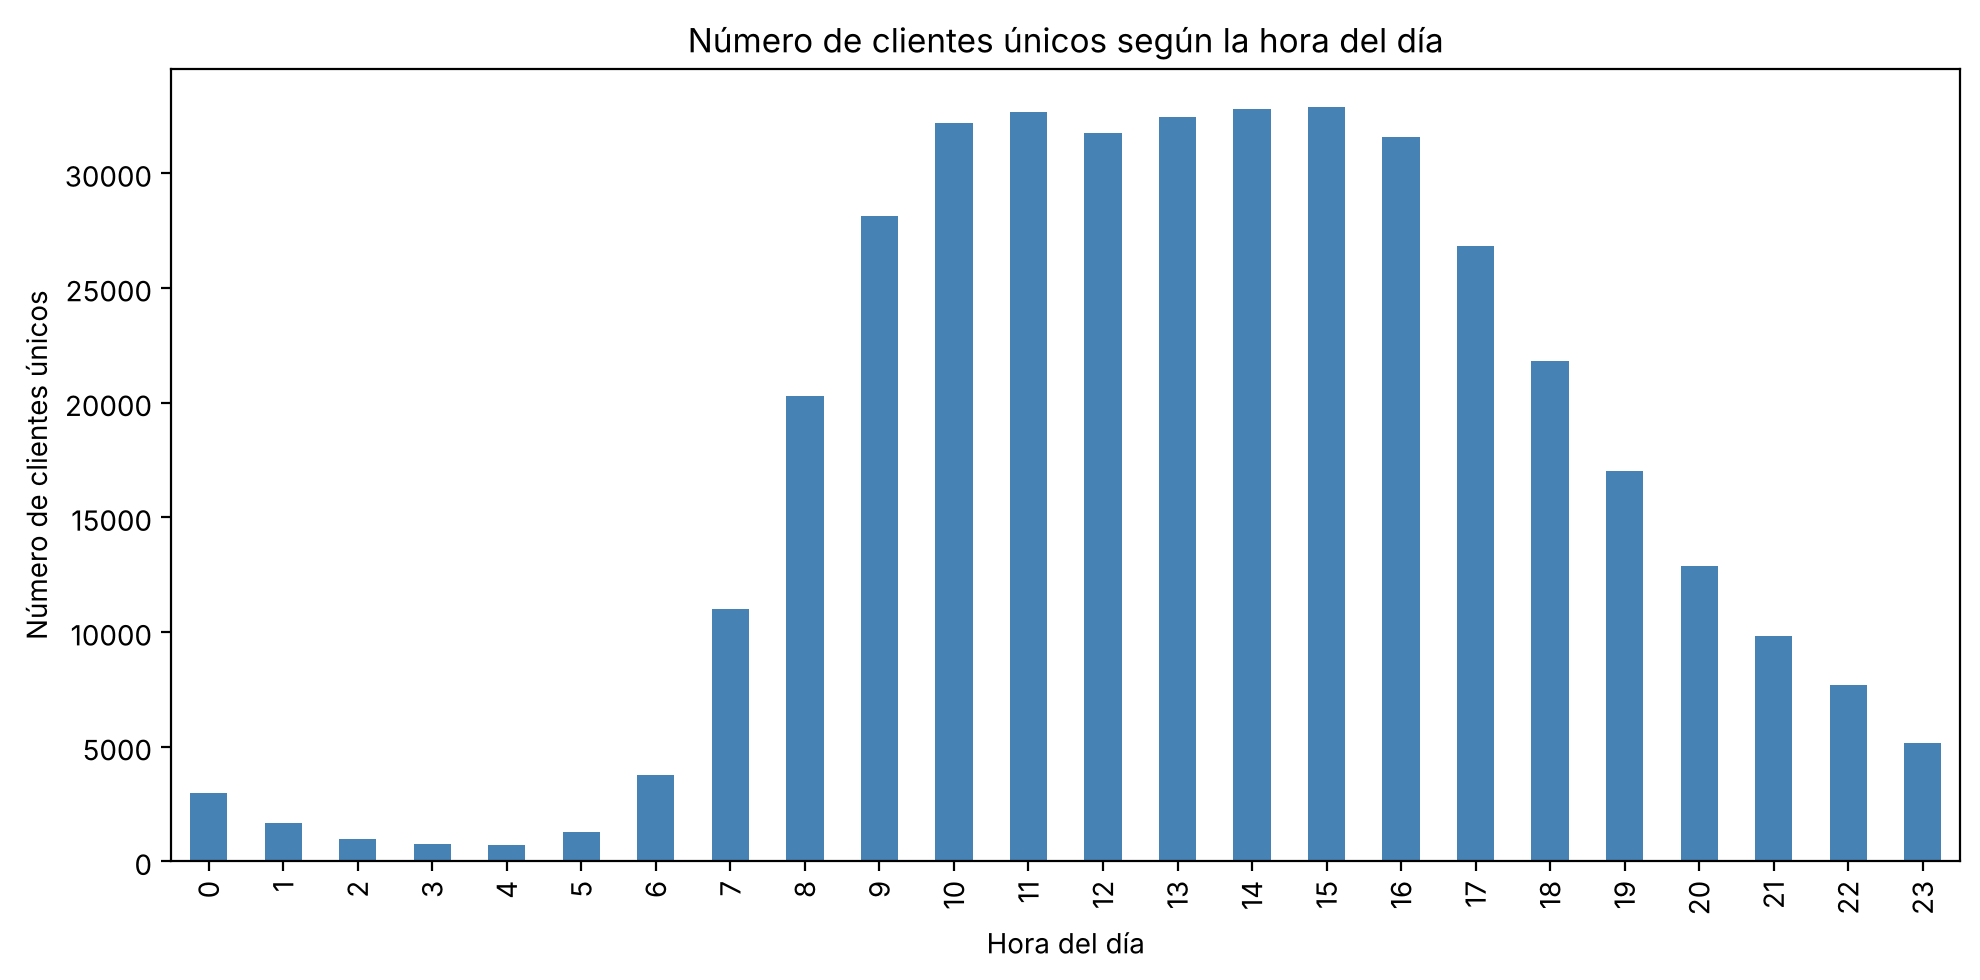

In [39]:
users_per_hour = instacart_orders.groupby('order_hour_of_day')[
    'user_id'].nunique().reindex(range(24), fill_value=0)

plt.figure(figsize=(10, 5))
users_per_hour.plot(kind='bar', color='steelblue')
plt.title('Número de clientes únicos según la hora del día')
plt.xlabel('Hora del día')
plt.ylabel('Número de clientes únicos')
plt.tight_layout()
plt.show()

El número de clientes únicos que hacen pedidos crece con fuerza a partir de las 6 a.m. y se mantiene en una meseta entre las 10 a.m. y las 3 p.m., con entre 32,000 y 33,000 clientes distintos por hora (el máximo es a las 3 p.m., con 32,894). Después decae progresivamente hacia la noche. La actividad mínima es de 2 a 4 a.m., con menos de 1,000 clientes por hora.


### [A3] ¿Qué día de la semana compran víveres las personas?


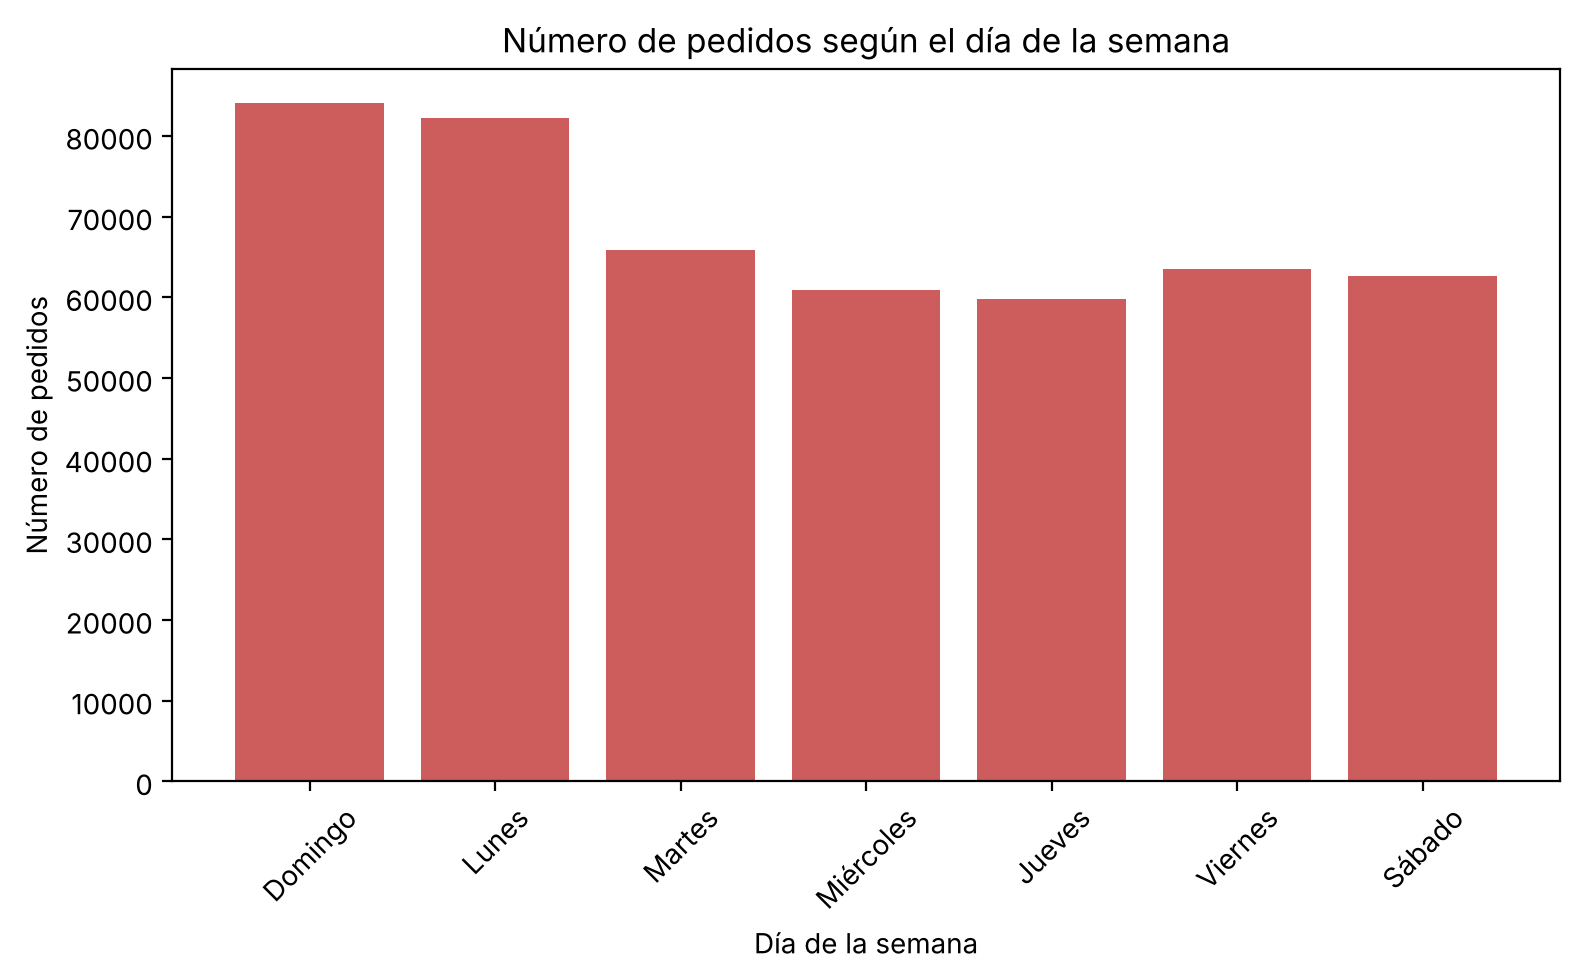

In [40]:
dow_counts = instacart_orders['order_dow'].value_counts().reindex(
    range(7), fill_value=0)
dow_labels = ['Domingo', 'Lunes', 'Martes',
              'Miércoles', 'Jueves', 'Viernes', 'Sábado']

plt.figure(figsize=(8, 5))
plt.bar(dow_labels, dow_counts.values, color='indianred')
plt.title('Número de pedidos según el día de la semana')
plt.xlabel('Día de la semana')
plt.ylabel('Número de pedidos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Domingo (84,090) y lunes (82,185) concentran claramente más pedidos que el resto de la semana; de martes a sábado el volumen se mantiene relativamente parejo, entre 59,800 y 65,800 pedidos.


### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.


count    450135.000000
mean         11.101814
std           9.190004
min           0.000000
25%           4.000000
50%           7.000000
75%          15.000000
max          30.000000
Name: days_since_prior_order, dtype: float64


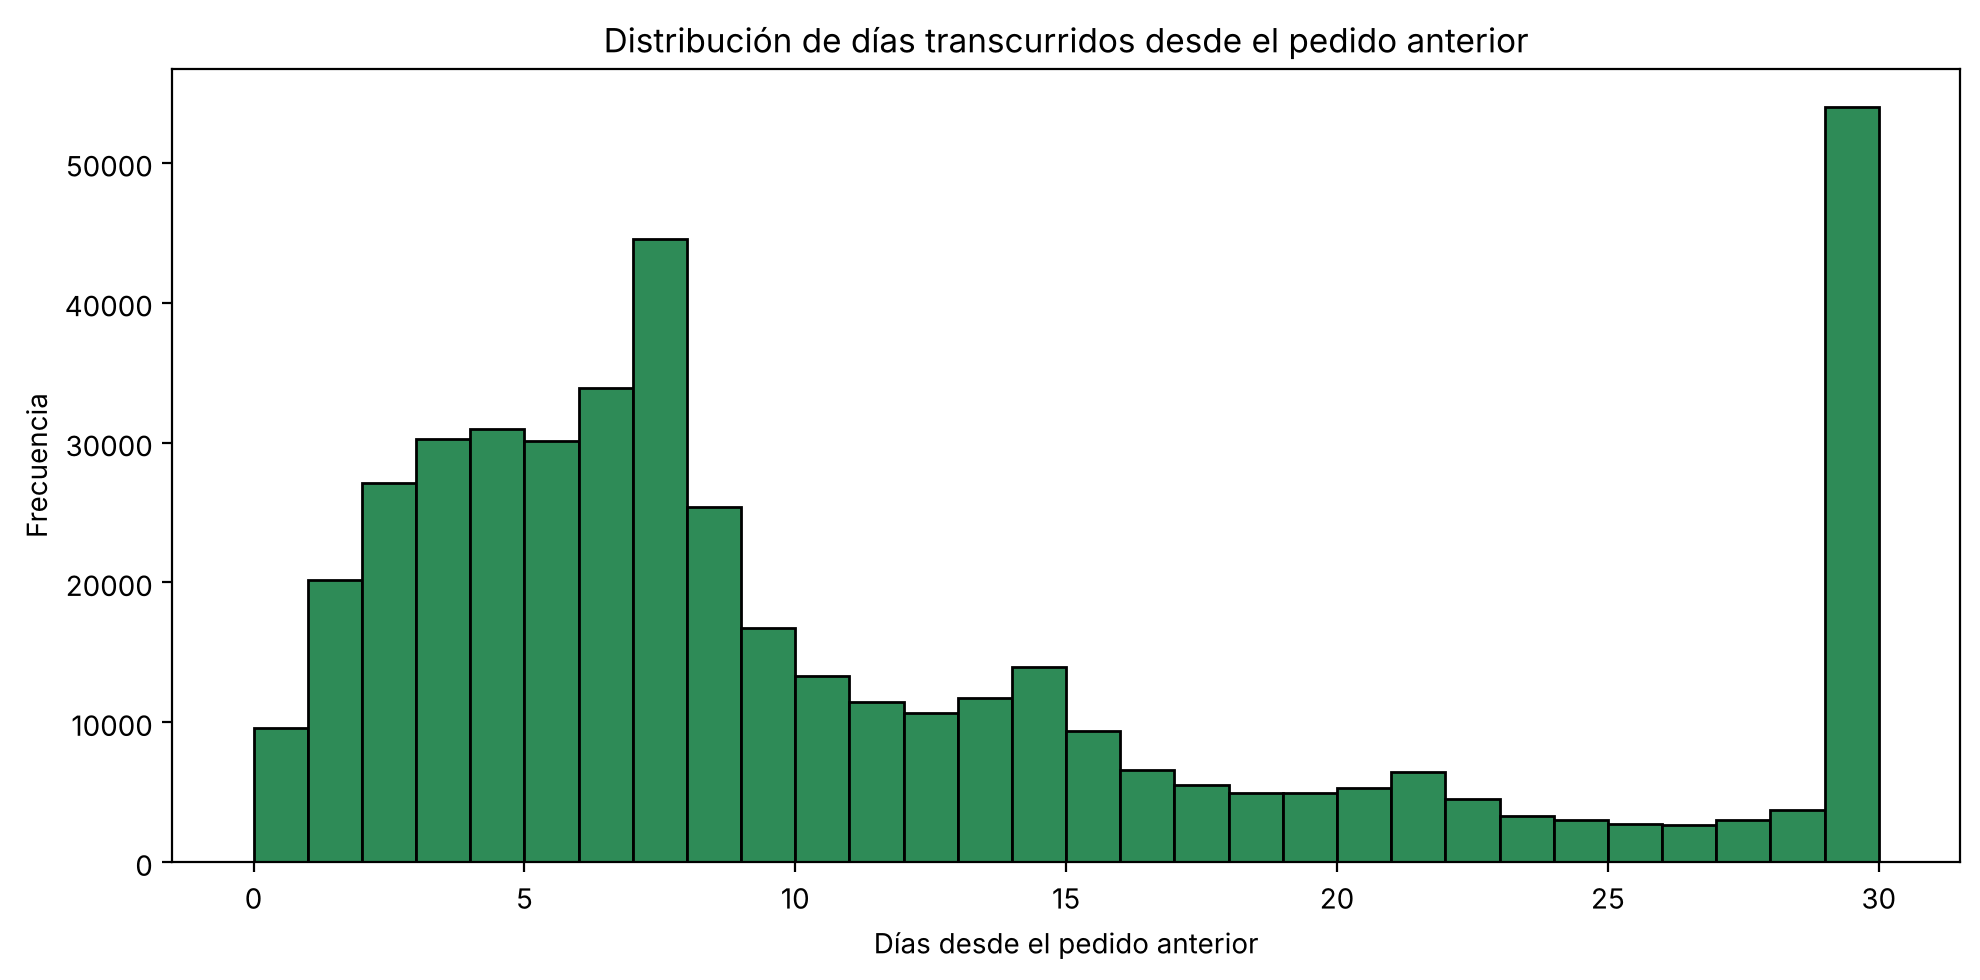

In [41]:
print(instacart_orders['days_since_prior_order'].describe())

plt.figure(figsize=(10, 5))
instacart_orders['days_since_prior_order'].plot(
    kind='hist', bins=30, color='seagreen', edgecolor='black')
plt.title('Distribución de días transcurridos desde el pedido anterior')
plt.xlabel('Días desde el pedido anterior')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

El resumen `.describe()` y el histograma calculan automáticamente sobre los 450,135 valores no nulos de `days_since_prior_order`, excluyendo los 28,817 primeros pedidos de cada cliente (donde este valor es `NaN` por definición, ya que no existe un pedido previo con el cual calcular la diferencia). Sobre esos valores no nulos, el mínimo es 0 días (pedidos el mismo día) y el máximo es 30. La mediana es 7 días: el patrón dominante es reabastecerse semanalmente. La barra en 30 está artificialmente elevada porque el dataset parece truncar ahí todo valor de "30 días o más", no porque exista un pico real de comportamiento exactamente a los 30 días.


# [B] Intermedio (deben completarse todos para aprobar)

1. ¿Existe alguna diferencia entre las distribuciones `'order_hour_of_day'` de los miércoles y los sábados? Traza gráficos de barra de `'order_hour_of_day'` para ambos días en la misma figura y describe las diferencias que observes.
2. Grafica la distribución para el número de órdenes que hacen los clientes (es decir, cuántos clientes hicieron solo 1 pedido, cuántos hicieron 2, cuántos 3, y así sucesivamente...).
3. ¿Cuáles son los 20 principales productos que se piden con más frecuencia (muestra su identificación y nombre)?


### [B1] Diferencia entre miércoles y sábados para `'order_hour_of_day'`. Traza gráficos de barra para los dos días y describe las diferencias que veas.


In [42]:
wed = instacart_orders[instacart_orders['order_dow'] ==
                       3]['order_hour_of_day'].value_counts().sort_index()
sat = instacart_orders[instacart_orders['order_dow'] ==
                       6]['order_hour_of_day'].value_counts().sort_index()

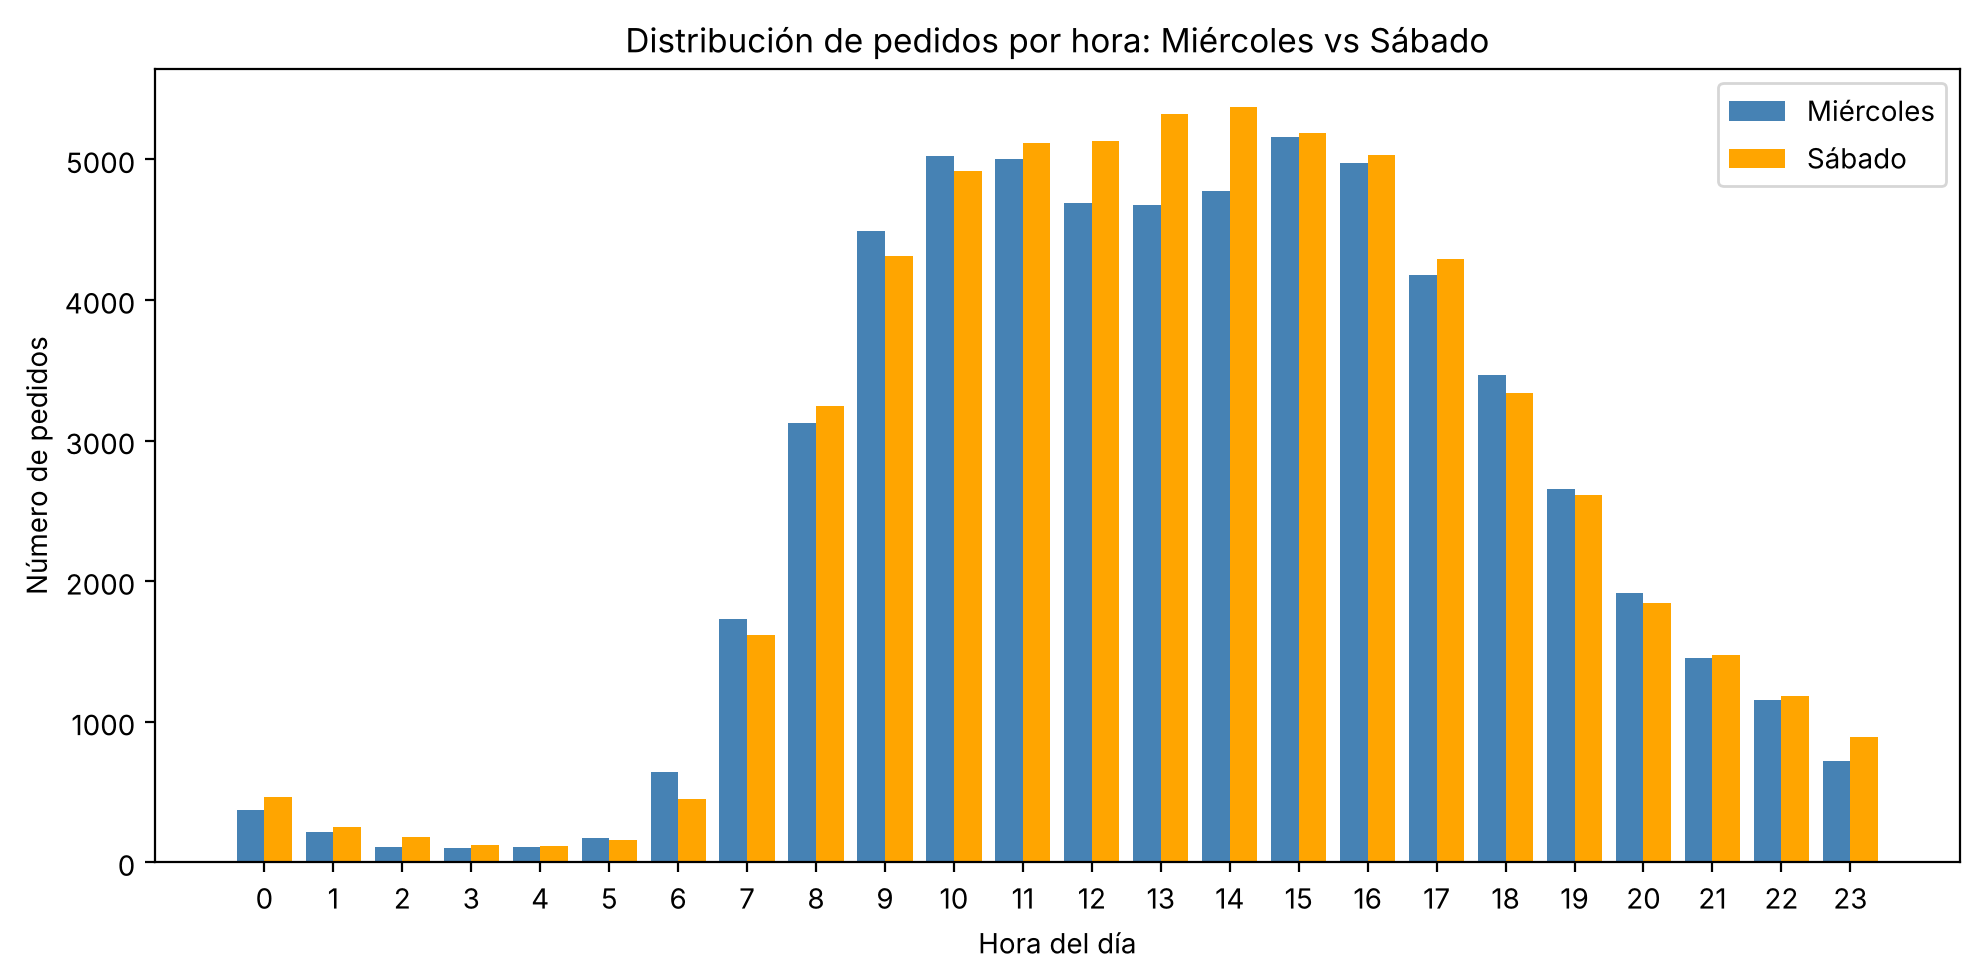

In [43]:
fig, ax = plt.subplots(figsize=(10, 5))
x = range(24)
width = 0.4
ax.bar([i-width/2 for i in x], wed.reindex(range(24), fill_value=0),
       width=width, label='Miércoles', color='steelblue')
ax.bar([i+width/2 for i in x], sat.reindex(range(24), fill_value=0),
       width=width, label='Sábado', color='orange')
ax.set_xticks(list(x))
ax.set_xlabel('Hora del día')
ax.set_ylabel('Número de pedidos')
ax.set_title('Distribución de pedidos por hora: Miércoles vs Sábado')
ax.legend()
plt.tight_layout()
plt.show()

In [44]:
print(wed.describe())

count      24.000000
mean     2537.375000
std      1994.351672
min       101.000000
25%       575.500000
50%      2284.500000
75%      4677.500000
max      5163.000000
Name: count, dtype: float64


In [45]:
print(sat.describe())

count      24.000000
mean     2610.375000
std      2075.716614
min       118.000000
25%       460.750000
50%      2228.500000
75%      4946.500000
max      5375.000000
Name: count, dtype: float64


Ambos días comparten la misma forma general (pico entre 10am-3pm, valle de madrugada), pero el sábado desplaza ligeramente el pico hacia horas más tardías (2-3pm vs 10-11am en miércoles) y mantiene más volumen relativo por la tarde/noche, coherente con un día no laboral donde la gente compra más tarde.


### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?


In [46]:
orders_per_customer = instacart_orders.groupby('user_id')['order_number'].max()
print(orders_per_customer.describe())

count    157437.000000
mean         15.577571
std          17.215517
min           1.000000
25%           4.000000
50%           9.000000
75%          20.000000
max         100.000000
Name: order_number, dtype: float64


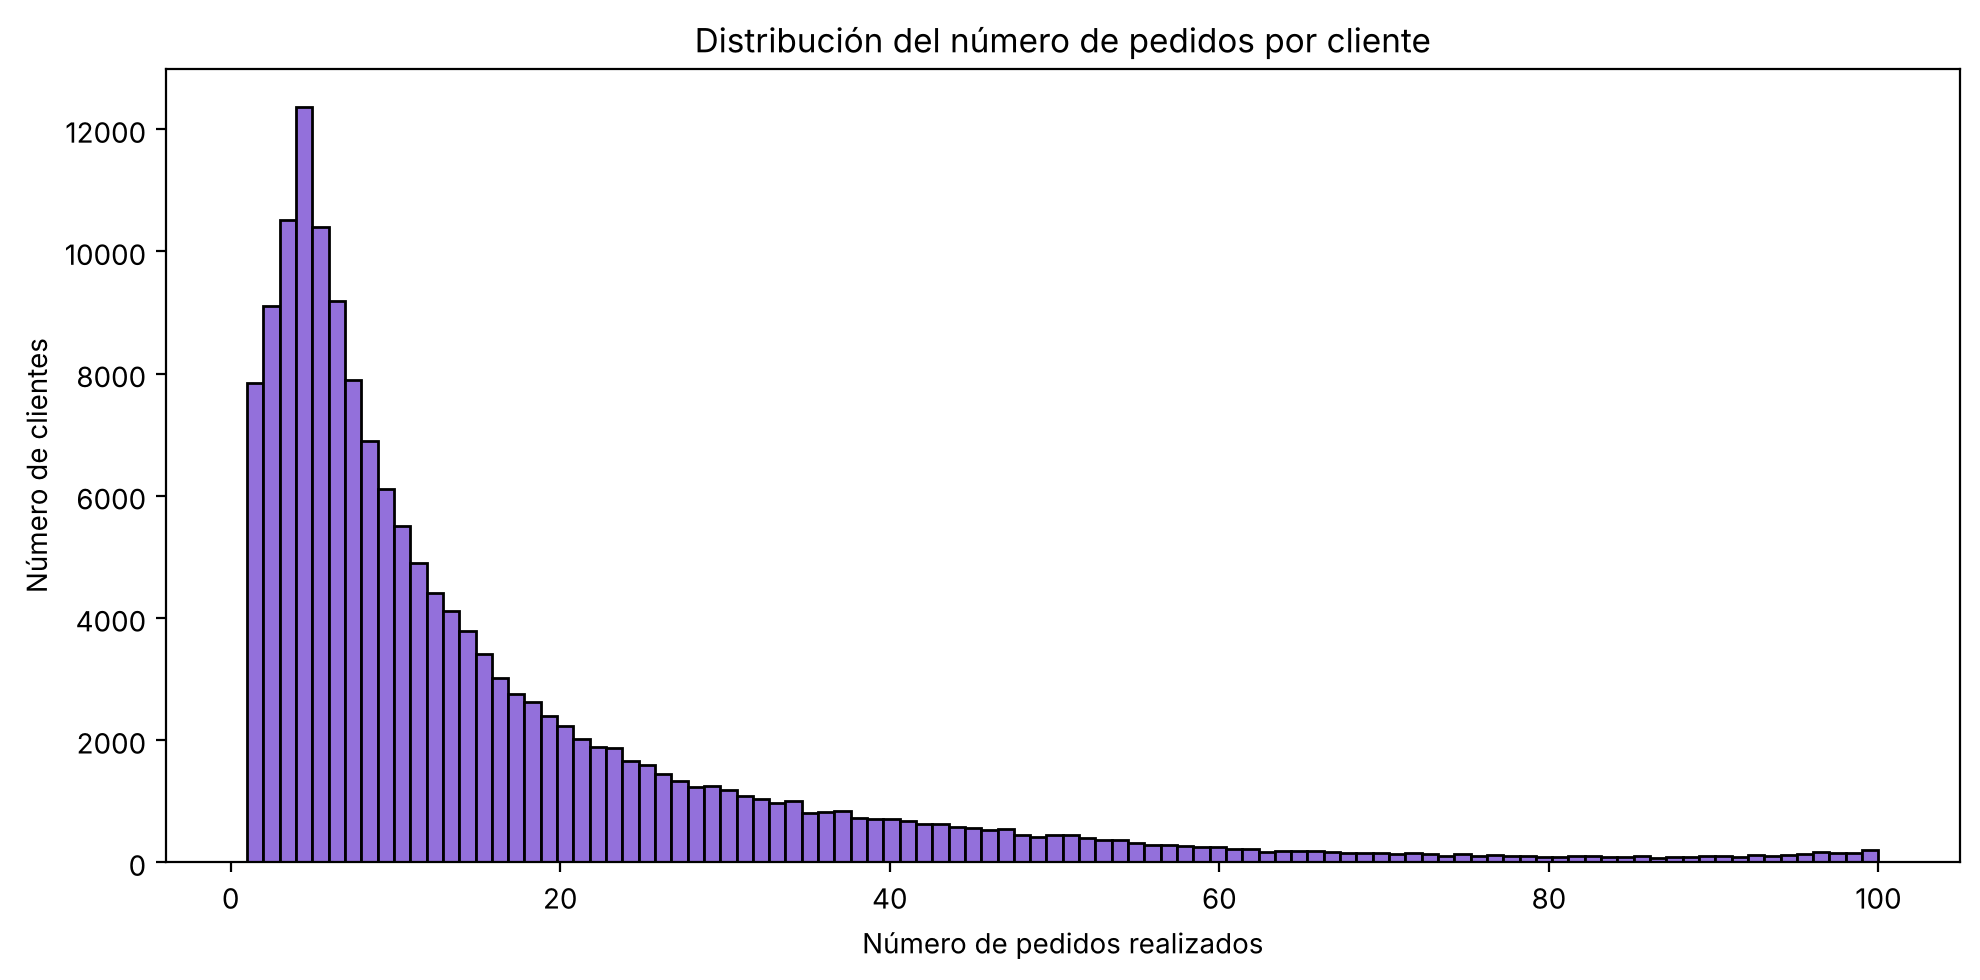

In [47]:
plt.figure(figsize=(10, 5))
orders_per_customer.plot(kind='hist', bins=orders_per_customer.max(
), color='mediumpurple', edgecolor='black')
plt.title('Distribución del número de pedidos por cliente')
plt.xlabel('Número de pedidos realizados')
plt.ylabel('Número de clientes')
plt.tight_layout()
plt.show()

Distribución muy sesgada a la derecha: mediana de 9 pedidos, pero con una cola larga hasta 100 (el máximo, probablemente un tope del dataset). La mayoría de los clientes son de bajo volumen (1-15 pedidos); pocos usuarios "power" concentran decenas de pedidos.


### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?


In [48]:
top_products = order_products.merge(
    products[['product_id', 'product_name']], on='product_id', how='left')

In [49]:
top20_named = top_products.groupby(
    ['product_id', 'product_name']).size().sort_values(ascending=False).head(20)
print(top20_named)

product_id  product_name            
24852       Banana                      66050
13176       Bag of Organic Bananas      53297
21137       Organic Strawberries        37039
21903       Organic Baby Spinach        33971
47209       Organic Hass Avocado        29773
47766       Organic Avocado             24689
47626       Large Lemon                 21495
16797       Strawberries                20018
26209       Limes                       19690
27845       Organic Whole Milk          19600
27966       Organic Raspberries         19197
22935       Organic Yellow Onion        15898
24964       Organic Garlic              15292
45007       Organic Zucchini            14584
39275       Organic Blueberries         13879
49683       Cucumber Kirby              13675
28204       Organic Fuji Apple          12544
5876        Organic Lemon               12232
8277        Apple Honeycrisp Organic    11993
40706       Organic Grape Tomatoes      11781
dtype: int64


El top está dominado por frutas y verduras frescas, casi todas orgánicas: Banana (66,050), Bag of Organic Bananas (53,297), Organic Strawberries (37,039), Organic Baby Spinach (33,971) y Organic Hass Avocado (29,773) encabezan la lista. El patrón es consistente con compras de reabastecimiento de productos frescos y perecederos.


# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?


### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?


In [50]:
items_per_order = order_products.groupby('order_id').size()
print(items_per_order.describe())

count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
dtype: float64


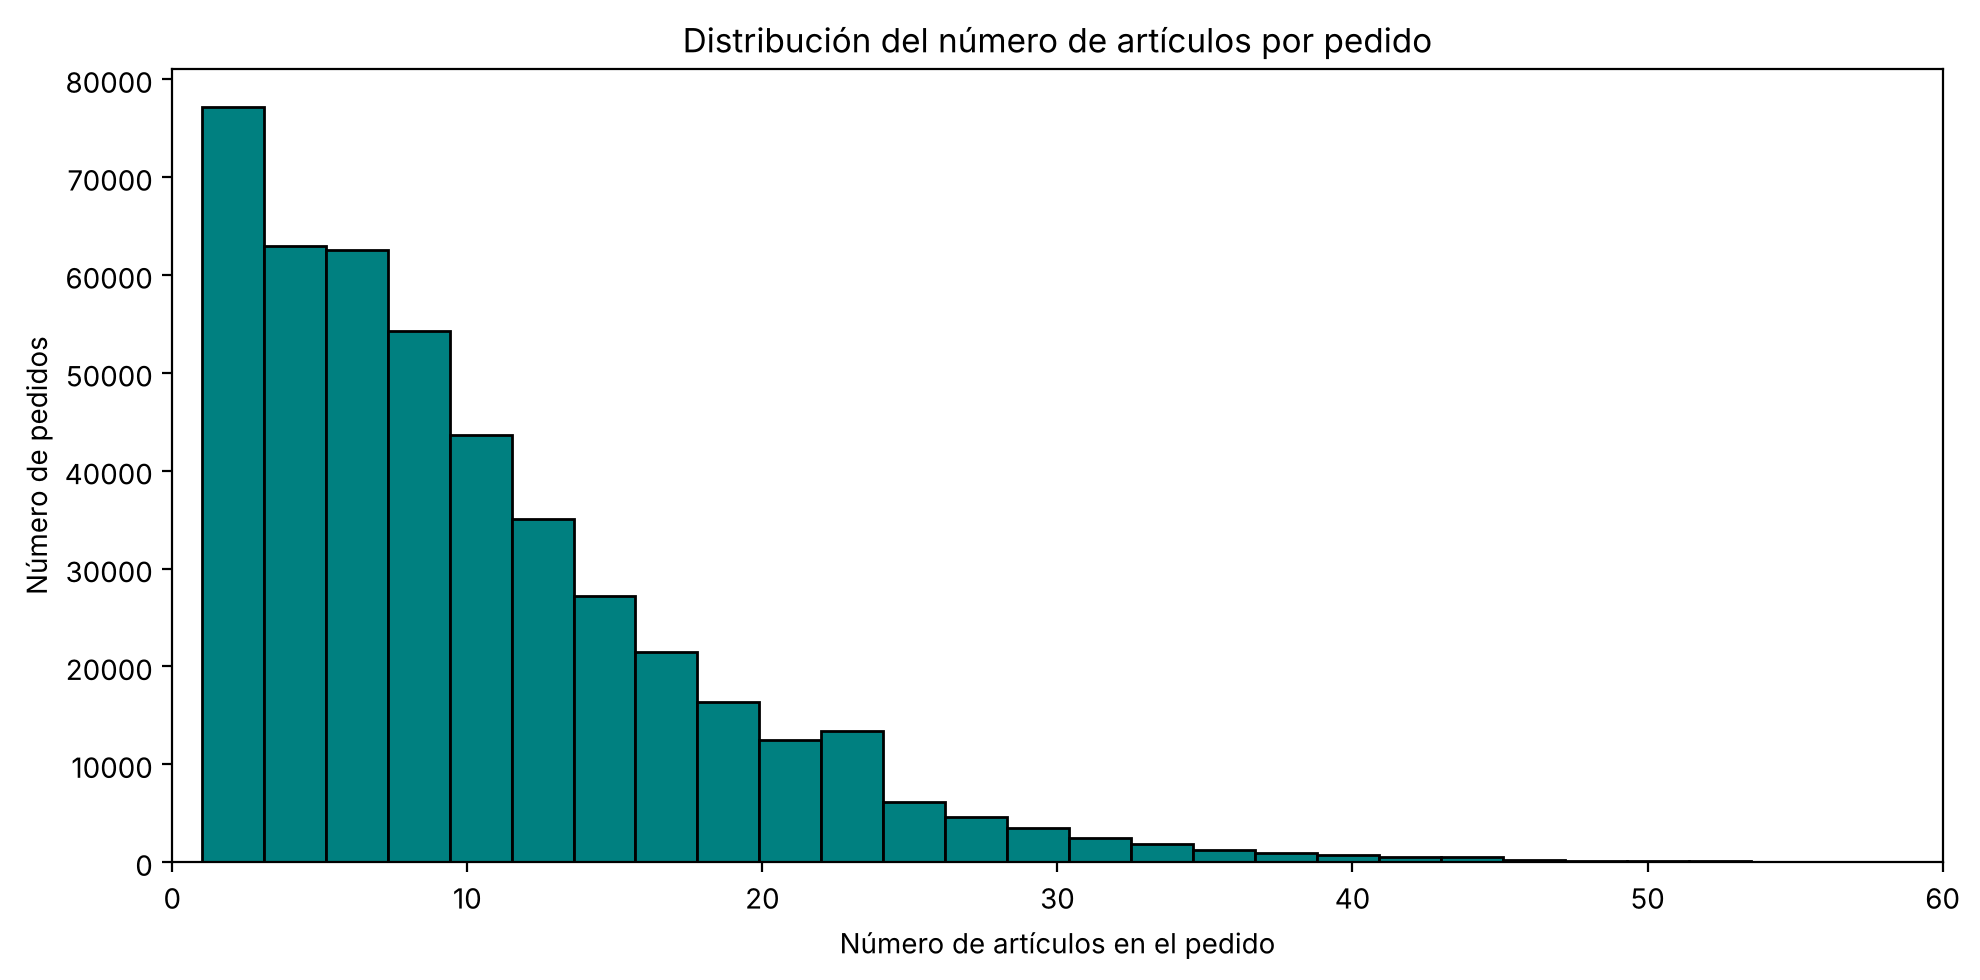

In [51]:
plt.figure(figsize=(10, 5))
items_per_order.plot(kind='hist', bins=60, color='teal', edgecolor='black')
plt.title('Distribución del número de artículos por pedido')
plt.xlabel('Número de artículos en el pedido')
plt.ylabel('Número de pedidos')
plt.xlim(0, 60)
plt.tight_layout()
plt.show()

Media de 10.1 artículos, mediana de 8. Distribución fuertemente sesgada a la derecha: la mayoría de los pedidos son pequeños (1-14 artículos), con una cola larga hacia carritos grandes (máximo 127).


### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?


In [52]:
reordered = order_products[order_products['reordered'] == 1]

In [53]:
top20_reorder = reordered.merge(
    products[['product_id', 'product_name']], on='product_id', how='left')

In [54]:
top20_reorder_counts = top20_reorder.groupby(
    ['product_id', 'product_name']).size().sort_values(ascending=False).head(20)
print(top20_reorder_counts)

product_id  product_name            
24852       Banana                      55763
13176       Bag of Organic Bananas      44450
21137       Organic Strawberries        28639
21903       Organic Baby Spinach        26233
47209       Organic Hass Avocado        23629
47766       Organic Avocado             18743
27845       Organic Whole Milk          16251
47626       Large Lemon                 15044
27966       Organic Raspberries         14748
16797       Strawberries                13945
26209       Limes                       13327
22935       Organic Yellow Onion        11145
24964       Organic Garlic              10411
45007       Organic Zucchini            10076
49683       Cucumber Kirby               9538
28204       Organic Fuji Apple           8989
8277        Apple Honeycrisp Organic     8836
39275       Organic Blueberries          8799
5876        Organic Lemon                8412
49235       Organic Half & Half          8389
dtype: int64


La lista es casi idéntica a la del top de productos más pedidos: Banana (55,763), Bag of Organic Bananas (44,450), Organic Strawberries (28,639)... Tiene sentido: los productos más comprados en general también son los que más se repiten, por ser básicos de consumo recurrente.


### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?


In [55]:
prod_stats = order_products.groupby('product_id').agg(
    total_orders=('order_id', 'count'),
    reorders=('reordered', 'sum')
)
prod_stats['reorder_rate'] = prod_stats['reorders'] / \
    prod_stats['total_orders']

In [56]:
prod_stats = prod_stats.merge(
    products[['product_id', 'product_name']], on='product_id', how='left')
print(prod_stats['reorder_rate'].describe())

count    45573.000000
mean         0.386707
std          0.272132
min          0.000000
25%          0.166667
50%          0.408163
75%          0.575758
max          1.000000
Name: reorder_rate, dtype: float64


In [57]:
print(prod_stats.sort_values('reorder_rate', ascending=False).head(10)
      [['product_name', 'total_orders', 'reorders', 'reorder_rate']])

                                           product_name  total_orders  \
26746                       Pomegranate Sangria Seltzer             1   
45503                                        Opo Squash             1   
45508                 Golden Wheat Deep Cleanse Shampoo             1   
22845                      Snack- Sweet Chili- Original             2   
22850                                     Clear Ammonia             1   
22795                       Dark Chocolate Coconut Bars             2   
21375  Fruit Spread- Chia- Strawberry- with Agave Syrup             1   
4363                       Instant Sea Vegetable Wakame             2   
37534                         Quart Freezer Slider Bags             3   
23421                      Bread & Butter Chips Pickles             1   

       reorders  reorder_rate  
26746         1           1.0  
45503         1           1.0  
45508         1           1.0  
22845         2           1.0  
22850         1           1.0  
2279

In [58]:
# Tabla final por producto: product_id, product_name y reorder_rate para todos los productos
product_reorder_table = prod_stats[['product_id', 'product_name', 'reorder_rate']].sort_values(
    'product_id').reset_index(drop=True)
product_reorder_table

,product_id,product_name,reorder_rate
0,1,Chocolate Sandwich Cookies,0.564286
1,2,All-Seasons Salt,0.000000
2,3,Robust Golden Unsweetened Oolong Tea,0.738095
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,0.510204
4,7,Pure Coconut Water With Orange,0.500000
...,...,...,...
45568,49690,HIGH PERFORMANCE ENERGY DRINK,0.800000
45569,49691,ORIGINAL PANCAKE & WAFFLE MIX,0.430556
45570,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,0.416667
45571,49693,SPRING WATER BODY WASH,0.440000


`product_reorder_table` contiene, para los 45,573 productos, su `product_id`, `product_name` y `reorder_rate`. La tasa promedio de repetición es 38.7% (mediana ~40.8%). Al ordenar por tasa descendente, los primeros puestos son productos con tasa 100% pero muy bajo volumen (1-3 pedidos totales), por lo que no son representativos: para un ranking confiable habría que filtrar productos con un mínimo de pedidos (ej. >100) antes de ordenar por tasa.


### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?


In [59]:
op_user = order_products.merge(
    instacart_orders[['order_id', 'user_id']], on='order_id', how='left')
user_stats = op_user.groupby('user_id').agg(
    total_items=('product_id', 'count'),
    reorders=('reordered', 'sum')
)
user_stats['reorder_rate'] = user_stats['reorders'] / user_stats['total_items']

In [60]:
print(user_stats['reorder_rate'].describe())

count    149626.000000
mean          0.494853
std           0.292685
min           0.000000
25%           0.272727
50%           0.500000
75%           0.724138
max           1.000000
Name: reorder_rate, dtype: float64


In [61]:
# Tabla final por usuario: user_id, total de artículos, recompras y reorder_rate
user_reorder_table = user_stats.reset_index(
)[['user_id', 'total_items', 'reorders', 'reorder_rate']]
user_reorder_table

,user_id,total_items,reorders,reorder_rate
0,2,26,1,0.038462
1,4,2,0,0.000000
2,5,12,8,0.666667
3,6,4,0,0.000000
4,7,14,13,0.928571
...,...,...,...,...
149621,206203,27,6,0.222222
149622,206206,21,15,0.714286
149623,206207,46,41,0.891304
149624,206208,125,87,0.696000


`user_reorder_table` contiene, para los 149,626 clientes, su `user_id`, el total de artículos comprados, cuántos fueron recompras y su `reorder_rate`. En promedio, el 49.5% de los artículos que compra cada cliente ya los había pedido antes (mediana también ~50%). Esto confirma un fuerte comportamiento de recompra/reabastecimiento a nivel de cliente individual, consistente con lo visto en C2 y C3.


### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?


In [62]:
first_in_cart = order_products[order_products['add_to_cart_order'] == 1]

In [63]:
top20_first = first_in_cart.merge(
    products[['product_id', 'product_name']], on='product_id', how='left')

In [64]:
top20_first_counts = top20_first.groupby(
    ['product_id', 'product_name']).size().sort_values(ascending=False).head(20)
print(top20_first_counts)

product_id  product_name               
24852       Banana                         15562
13176       Bag of Organic Bananas         11026
27845       Organic Whole Milk              4363
21137       Organic Strawberries            3946
47209       Organic Hass Avocado            3390
21903       Organic Baby Spinach            3336
47766       Organic Avocado                 3044
19660       Spring Water                    2336
16797       Strawberries                    2308
27966       Organic Raspberries             2024
44632       Sparkling Water Grapefruit      1914
49235       Organic Half & Half             1797
47626       Large Lemon                     1737
196         Soda                            1733
38689       Organic Reduced Fat Milk        1397
26209       Limes                           1370
12341       Hass Avocados                   1340
5785        Organic Reduced Fat 2% Milk     1310
27086       Half & Half                     1309
43352       Raspberries      

Banana (15,562) y Bag of Organic Bananas (11,026) también dominan como primer artículo añadido al carrito, muy por encima del resto. Esto sugiere que son de los productos con mayor "top-of-mind" o que suelen estar al inicio de la ruta de compra habitual del cliente.


### Conclusión general del proyecto

El análisis confirma un comportamiento de compra centrado en el reabastecimiento recurrente de productos frescos: la actividad se concentra en horario diurno (10am-3pm) y en fines de semana/lunes, con un ciclo típico de recompra semanal (mediana de 7 días entre pedidos). Casi la mitad de los artículos que compra cada cliente son repeticiones, y ese patrón de recompra está dominado por un puñado de productos básicos, bananas, espinaca orgánica, aguacates, fresas orgánicas, que aparecen consistentemente como los más pedidos, los más re-pedidos y los primeros en añadirse al carrito, lo que indica que son la base habitual de la lista de compras de la mayoría de los usuarios.
